In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [ ]:
print(df.shape[0])
print(df.shape[1])

6433
14


In [ ]:
#2.Check missing values
missing_values = df.isnull().sum()

print(missing_values)

print(missing_values[missing_values > 0])

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [ ]:
#Impute missing values

#identify numerical columns and fill using median
numeric_columns = df.select_dtypes(include='number').columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())


In [ ]:
#identify categorical columns and fill using mode
categorical_columns = df.select_dtypes(include=['object', 'category']).columns

for column in categorical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].mode()[0])



In [ ]:
#Convert pickup into datetime format
df['pickup'] = pd.to_datetime (df['pickup'],errors='coerce')

In [ ]:
#Remove rows with missing critical values
df = df.dropna(subset=['pickup', 'fare'])

print(df['pickup'].dtype)

datetime64[ns]


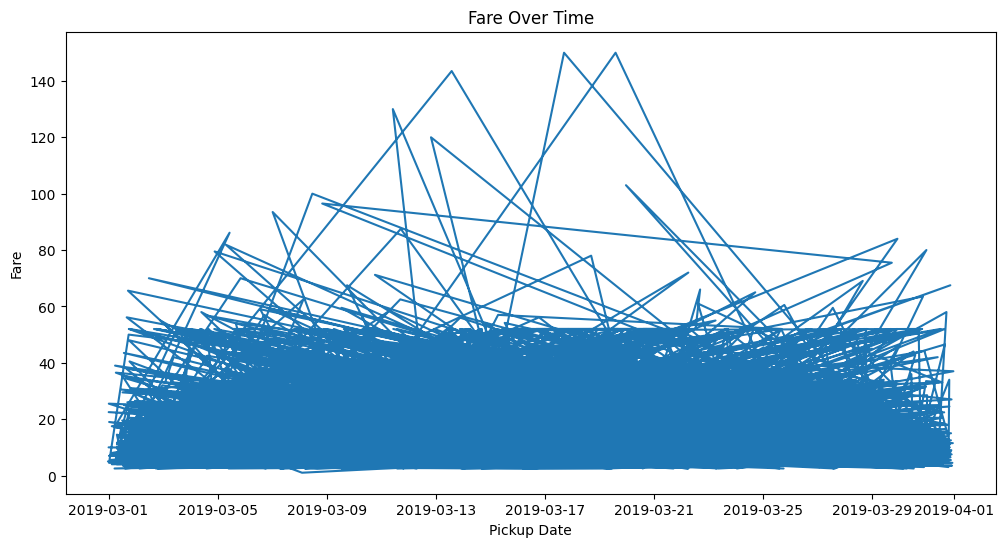

In [ ]:
#3) Visualizations using Matplotlib/Pandas Plot

#Line Chart
plt.figure(figsize=(12, 6))
plt.plot(df['pickup'], df['fare'])
plt.title('Fare Over Time')
plt.xlabel('Pickup Date')
plt.ylabel('Fare')

plt.show()



pickup_borough
Bronx         2078.91
Brooklyn      6327.48
Manhattan    58753.42
Queens       16382.06
Name: fare, dtype: float64


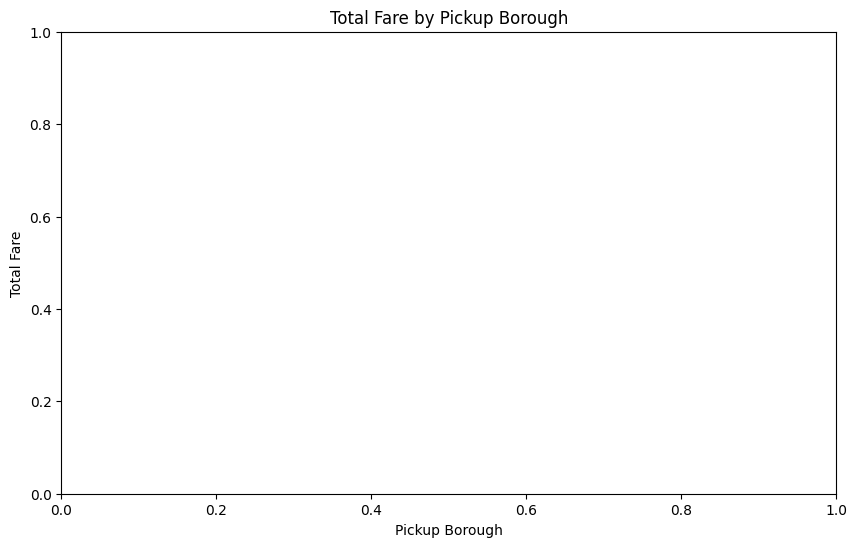

In [ ]:
#Bar Chart
borough_fare = df.groupby('pickup_borough')['fare'].sum()

print(borough_fare)

plt.figure(figsize=(10, 6))

borough_fare.plot.bar

plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.title('Total Fare by Pickup Borough')


plt.show()

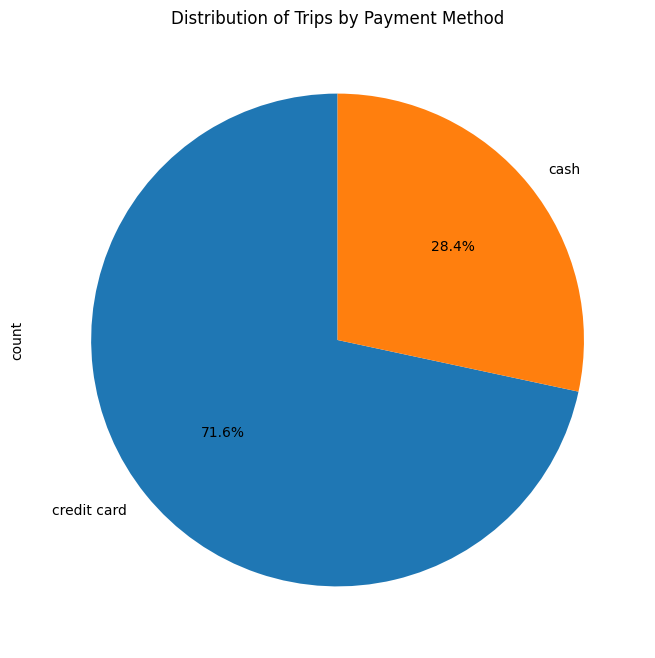

In [ ]:
#pie chart
payment_counts = df['payment'].value_counts()

plt.figure(figsize=(8, 8))

payment_counts.plot.pie(autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Trips by Payment Method')

plt.show()

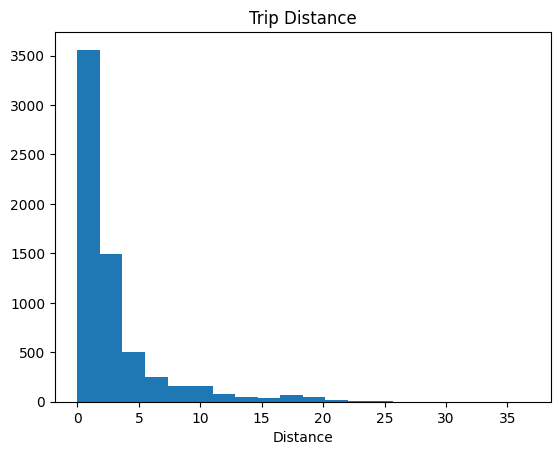

In [ ]:
#Histogram
plt.hist(df['distance'].dropna(), bins=20)
plt.title('Trip Distance')
plt.xlabel('Distance')
plt.show()

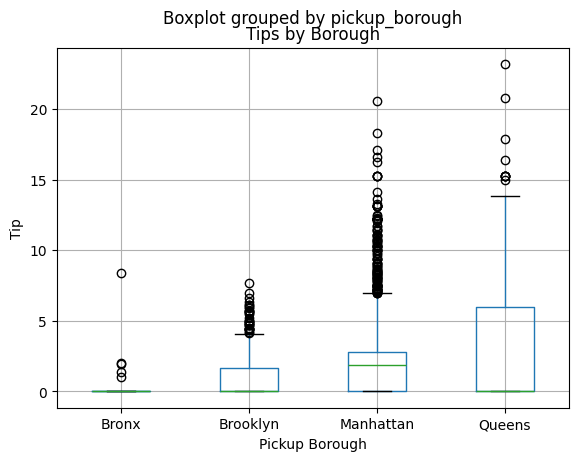

In [ ]:
#Box plot
df.boxplot(column='tip', by='pickup_borough')
plt.title('Tips by Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip')
plt.show()

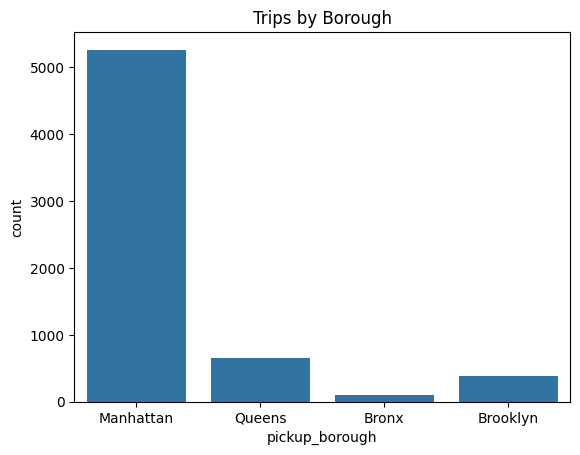

In [ ]:
#Visualizations using Seaborn
sns.countplot(data=df, x='pickup_borough')
plt.title('Trips by Borough')
plt.show()

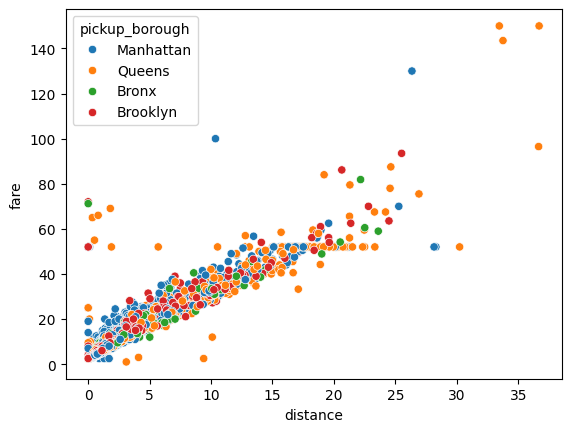